In [ ]:
%%capture
%env AWS_PROFILE=kmnlp

In [ ]:
import sys
sys.path.append("../src")

In [ ]:
import json
import os
from os.path import basename, dirname, splitext
from time import perf_counter

import fsspec
import humanize.filesize
import numpy as np
import seaborn as sns
import s3fs
import xarray as xr
from dask.distributed import Client, LocalCluster
from fsspec.implementations.reference import ReferenceFileSystem
from matplotlib import pyplot as plt
from rich import print as rprint
from tqdm import tqdm

In [ ]:
%matplotlib inline
sns.reset_defaults()

In [ ]:
cluster = LocalCluster()
client = cluster.get_client()

In [ ]:
experiment_name = "scaling_atmos"
benchmarks_path = f"./data/{experiment_name}.json"
os.makedirs(dirname(benchmarks_path), exist_ok=True)
benchmarks_data = {}

In [ ]:
# with open(benchmarks_path, "r") as f:
#     benchmarks_data = json.load(f)
# data = benchmarks_data

In [ ]:
uri = "s3://data-c6c22a2e42294c11b52ee7f0c792c071/noaa-cdr-ocean-nearsurface-atmos-profiles-pds/daily/zarr_reference_final.parquet"

In [ ]:
def load_zarr_ds(uri: str) -> xr.Dataset:
    ref_fs = ReferenceFileSystem(uri, remote_protocol="s3", lazy=True)
    mapper = ref_fs.get_mapper()
    return xr.open_zarr(mapper, consolidated=False)

In [ ]:
ds = load_zarr_ds(uri)

In [ ]:
da = ds["air_temperature"].unify_chunks()

In [ ]:
# limit to single spatial chunk to reduce size
spatial_window_pixel_bounds = {
    "lat": slice(0, 200),
    "lon": slice(0, 200),
}

In [13]:
# time_lims = 2**np.arange(11)
time_lims = 8 * 2**np.arange(11)
time_lims

array([   8,   16,   32,   64,  128,  256,  512, 1024, 2048, 4096, 8192])

In [ ]:
data = {}
offset = 0
with tqdm(time_lims.tolist()) as bar:
    for t_lim in bar:
        bar.set_postfix_str(f"{t_lim=}")
        da_sliced = da.isel(**spatial_window_pixel_bounds, time=slice(offset, offset + t_lim))
        tic = perf_counter()
        _ = da_sliced.mean().compute()
        toc = perf_counter()
        data[t_lim] = {
            "bytes": da_sliced.nbytes,
            "time": toc - tic,
            "t_lim": t_lim
        }
        offset += t_lim

In [15]:
data

{8: {'bytes': 1280000, 'time': 3.9956190760003665, 't_lim': 8},
 16: {'bytes': 2560000, 'time': 2.1415354149999075, 't_lim': 16},
 32: {'bytes': 5120000, 'time': 1.2011513309998918, 't_lim': 32},
 64: {'bytes': 10240000, 'time': 1.5981326780001837, 't_lim': 64},
 128: {'bytes': 20480000, 'time': 2.7880629770002088, 't_lim': 128},
 256: {'bytes': 40960000, 'time': 4.196607256000334, 't_lim': 256},
 512: {'bytes': 81920000, 'time': 7.327399370999956, 't_lim': 512},
 1024: {'bytes': 163840000, 'time': 12.466383250000035, 't_lim': 1024},
 2048: {'bytes': 327680000, 'time': 26.497964478000085, 't_lim': 2048},
 4096: {'bytes': 655360000, 'time': 57.03372101600007, 't_lim': 4096},
 8192: {'bytes': 1310720000, 'time': 136.3220929449999, 't_lim': 8192}}

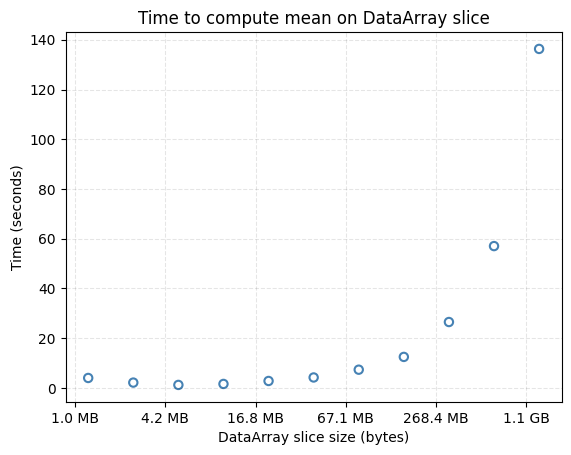

In [28]:
plt.close("all")
fig, ax = plt.subplots()

x = np.array([d["bytes"] for d in data.values()])
y = np.array([d["time"] for d in data.values()])

ax.scatter(x, y, marker="o", fc="none", ec="steelblue", lw=1.5, alpha=1)
ax.set_xscale("log", base=2)
# ax.set_yscale("log")
xticks = 2**np.arange(20, 32, 2)
# xticks = ax.get_xticks()
ax.set_xticks(ticks=xticks, labels=[humanize.filesize.naturalsize(v) for v in xticks])
ax.set_xlabel("DataArray slice size (bytes)")
ax.set_ylabel("Time (seconds)")
ax.set_title("Time to compute mean on DataArray slice")
plt.grid(ls="--", c="k", alpha=0.1)
plt.show()

---

In [ ]:
benchmarks_data = data
with open(benchmarks_path, "w") as f:
    json.dump(benchmarks_data, f, indent=2)